# Card: undoable edits in a Godot editor plugin

Your UI never changes the data itself. It tells the undo manager what the new and old values are; Godot applies them, and one signal redraws the UI.

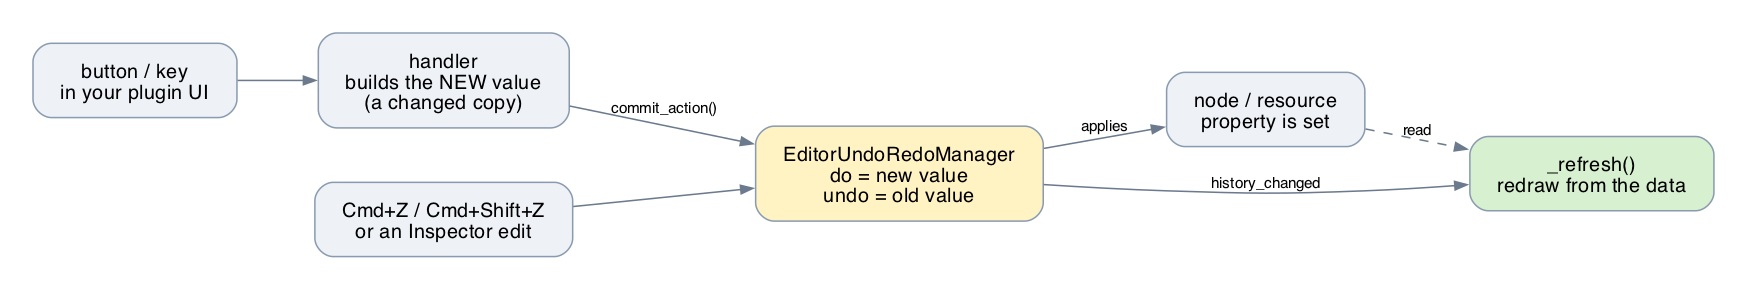

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  rankdir=LR;
  node [shape=box, style="rounded,filled", fillcolor="#eef2f7", fontname="Helvetica"];
  edge [fontname="Helvetica", fontsize=10];
  click [label="button / key\nin your plugin UI"];
  handler [label="handler\nbuilds the NEW value\n(a changed copy)"];
  undo [label="EditorUndoRedoManager\ndo = new value\nundo = old value", fillcolor="#fff3c4"];
  data [label="node / resource\nproperty is set"];
  refresh [label="_refresh()\nredraw from the data", fillcolor="#d7f0d0"];
  keys [label="Cmd+Z / Cmd+Shift+Z\nor an Inspector edit"];
  click -> handler;
  handler -> undo [label="commit_action()"];
  keys -> undo;
  undo -> data [label="applies"];
  undo -> refresh [label="history_changed"];
  data -> refresh [label="read", style=dashed];
}
```

</details>

| Step | General recipe | In the RPGM plugin (Delete a command) |
|---|---|---|
| 1 | Get the manager: `EditorInterface.get_editor_undo_redo()` | `_commit_lambda_queue` |
| 2 | Build the new value **without touching the live one**. Arrays and dictionaries need `duplicate()` | `_get_lambda_queue().duplicate()`, then `remove_at(index)` |
| 3 | `create_action("Name shown in Edit > Undo")` | `"Delete Command"` |
| 4 | `add_do_property(object, property, new_value)` | node, `on_action`, the changed copy |
| 5 | `add_undo_property(object, property, old_value)` | node, `on_action`, the live array |
| 6 | `commit_action()`: Godot runs the "do" now | the node gets the copy |
| 7 | Redraw from **one** place: connect `history_changed` to a refresh function | `_refresh()` redraws tabs, toolbar, list, values |
| **Result** | Undo / redo work, the scene is marked unsaved, and the UI cannot drift from the data | Cmd+Z brings the command back and the list updates by itself |

**Three things that go wrong**

- Changing the live array and passing it as both do and undo: undo does nothing. Change a `duplicate()`.
- Setting the property directly (`node.x = 5`): no undo, and the scene is not marked unsaved. Always go through an action.
- Redrawing inside the button handler: the UI goes stale after Cmd+Z or an Inspector edit. Redraw only from `history_changed`.

**Two extras used in the plugin**

- `add_do_method` / `add_undo_method` do the same for function calls instead of properties.
- `create_action(name, UndoRedo.MERGE_ENDS, context_node)`: merging turns a slider drag into one undo step, and the context node puts the edit in that scene's history (needed when the edited object is a brand-new resource with no path).
